## Evaluation and validation of the effective borefield thermal resistance

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from time import perf_counter

import pygfunction3 as gt3
import pygfunction as gt

#### Borefield parameters
3 fields of 1, 3, 5 boreholes connected in series.

In [2]:
# Borehole dimensions
L = 150.        # Borehole length (in meters)
D = 4.          # Borehole buried depth (in meters)
r_b = 0.075     # Borehole radius (in meters)
# Positions (x, y) of the boreholes on the horizontal plane (in meters)
B = 7.5         # Borehole spacing (in meters)
n_boreholes = np.array([1, 3, 5], dtype=int)
p_head = np.stack((np.arange(np.max(n_boreholes)) * B, np.zeros(np.max(n_boreholes))), axis=1)
fields = [gt3.Borefield(L, D, r_b, p_head[:n]) for n in n_boreholes]
fields_reversed = [gt3.Borefield(L, D, r_b, p_head[:n][::-1]) for n in n_boreholes]
# Borehole connectivity (boreholes are connected in series)
borehole_connectivity = np.arange(-1, n_boreholes[-1] - 1)

# Pipe dimensions
# Pipe outer radius (m)
r_p_out = 0.02
# Pipe inner radius (m)
r_p_in = 0.015

# Pipe positions
# Shank spacing
shank = 0.05
# Single U-tube
p_pipe = [(-shank, 0.0), (shank, 0.0)]

# Pipe properties
k_p = 0.4           # Pipe thermal conductivity (W/m.K)
epsilon = 1e-6      # Pipe roughness (in meters)

# Ground properties
k_s = 2.0           # Ground thermal conductivity (W/m.K)

# Grout properties
k_b = 1.0           # Grout thermal conductivity (W/m.K)

#### Fluid Properties
The fluid is propylene-glycol (20%).

In [3]:
# Fluid mass flow rate (in kg/s)
m_flow = np.linspace(0.01, 1.0, num=100)
T_nominal = 20.
x = 0.2
fluid = gt3.Fluid.from_scp(
    'PropyleneGlycol', T_nominal, x=x
)
cp_f = fluid.specific_heat()  # Fluid specific heat capacity (in J/kg.K)

#### Solution using pygfunction v3

In [4]:
pipe = gt3.SingleUTube(p_pipe, r_p_in, r_p_out, r_b, fluid, k_s, k_b, k_p, epsilon, J=2)
pipe_reversed = gt3.SingleUTube(p_pipe[::-1], r_p_in, r_p_out, r_b, fluid, k_s, k_b, k_p, epsilon, J=2)
R_field = []
for field in fields:
    network = gt3.Network(field, pipe, borehole_connectivity=borehole_connectivity[:field.n_boreholes])
    R_field.append(np.array([network.effective_borefield_thermal_resistance(_m_flow) for _m_flow in m_flow]))

R_field_reversed = []
for field in fields_reversed:
    network = gt3.Network(field, pipe_reversed, borehole_connectivity=borehole_connectivity[:field.n_boreholes])
    R_field_reversed.append(np.array([network.effective_borefield_thermal_resistance(-_m_flow) for _m_flow in m_flow]))

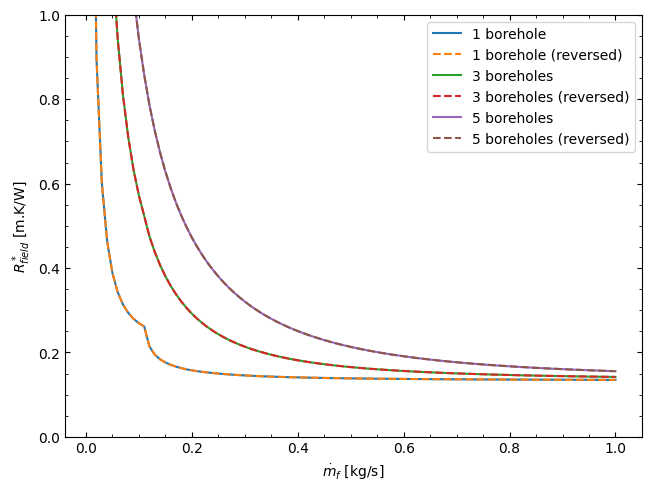

In [5]:
fig, ax = plt.subplots(constrained_layout=True)
ax = gt3.plot._format_axis(ax, [r'$\dot{m}_f$ [kg/s]', r'$R_{field}^*$ [m.K/W]'])
for _R_field, _R_field_reversed, n in zip(R_field, R_field_reversed, n_boreholes):
    ax.plot(m_flow, _R_field, label=f'{n} boreholes' if n > 1 else f'{n} borehole')
    ax.plot(m_flow, _R_field_reversed, '--', label=f'{n} boreholes (reversed)' if n > 1 else f'{n} borehole (reversed)')
ax.set_ylim([0, 1.])
ax.legend()
plt.show()

#### Solution using pygfunction v2

In [6]:
R_field_pygfunction = []
for _n in n_boreholes:
    field_pygfunction = gt.borefield.Borefield(L, D, r_b, p_head[:_n, 0], p_head[:_n, 1])
    _bore_connectivity = [i - 1 for i in range(_n)]
    _R_field = []
    for _m_flow in m_flow:
        # Pipe thermal resistance
        R_p = gt.pipes.conduction_thermal_resistance_circular_pipe(
                r_p_in, r_p_out, k_p)
        # Fluid to inner pipe wall thermal resistance (Single U-tube)
        h_f = gt.pipes.convective_heat_transfer_coefficient_circular_pipe(
                _m_flow, r_p_in, fluid.viscosity(), fluid.density(), fluid.conductivity(), fluid.specific_heat(), epsilon)
        R_f = 1.0 / (h_f * 2 * np.pi * r_p_in)

        # Single U-tube, same for all boreholes in the bore field
        UTubes = []
        for borehole in field_pygfunction:
            SingleUTube = gt.pipes.SingleUTube(
                p_pipe, r_p_in, r_p_out, borehole, k_s, k_b, R_f + R_p)
            UTubes.append(SingleUTube)
        network = gt.networks.Network(
            field_pygfunction,
            UTubes,
            bore_connectivity=_bore_connectivity)

        # Effective bore field thermal resistance
        _R_field.append(
            gt.networks.network_thermal_resistance(
                network, _m_flow, cp_f)
        )
    R_field_pygfunction.append(np.array(_R_field))

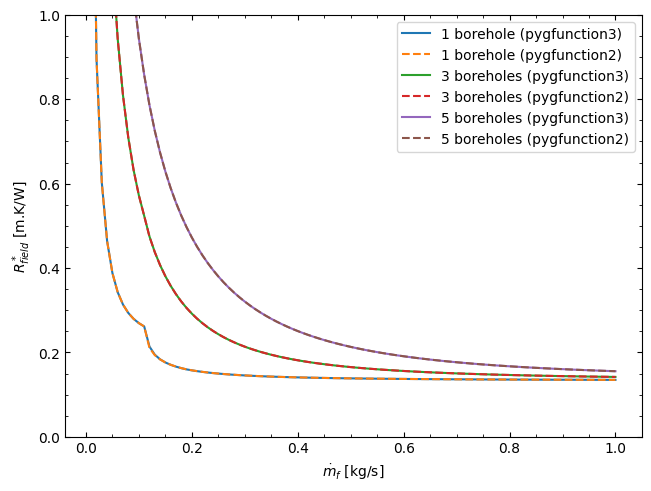

In [7]:
fig, ax = plt.subplots(constrained_layout=True)
ax = gt3.plot._format_axis(ax, [r'$\dot{m}_f$ [kg/s]', r'$R_{field}^*$ [m.K/W]'])
for _R_field, _R_field_pygfunction, n in zip(R_field, R_field_pygfunction, n_boreholes):
    ax.plot(m_flow, _R_field, label=f'{n} boreholes (pygfunction3)' if n > 1 else f'{n} borehole (pygfunction3)')
    ax.plot(m_flow, _R_field_pygfunction, label=f'{n} boreholes (pygfunction2)' if n > 1 else f'{n} borehole (pygfunction2)', linestyle='--')
ax.set_ylim([0, 1.])
ax.legend()
plt.show()